# Анализ риска инвестиционного портфеля методом Монте-Карло

**Pet-проект для портфолио Data Scientist / Quantitative Finance**

**Цель:** показать практическое применение метода Монте-Карло для количественной оценки инвестиционного риска и неопределённости на реальных рыночных данных.

###датасеты на Kaggle 
- [Analyze Your Stock Portfolio for Risks and Returns](https://www.kaggle.com/datasets/abdelazizsami/analyze-your-stock-portfolio-for-risks-and-returns) — дневные цены FAANG 2020–2023
- Аналогичные публичные датасеты с историческими ценами технологических гигантов

В этом проекте данные загружаются **вживую через `yfinance`** (тикеры FAANG + Microsoft). Так анализ остаётся полностью воспроизводимым без ручной загрузки файлов.

1. Загрузка данных и разведочный анализ доходностей и корреляций  
2. Оценка параметров (вектор средних + ковариационная матрица)  
3. Многоактивная симуляция Монте-Карло (геометрическое броуновское движение с корреляциями)  
4. Метрики риска: VaR, CVaR (Expected Shortfall), вероятность убытка, перцентили  
5. Визуализация траекторий и распределения конечной стоимости  
6. Интерпретация результатов и выводы для портфеля  


In [1]:
import sys
sys.path.append("..")

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data_loader import load_portfolio_data, compute_returns, get_portfolio_params
from src.simulation import run_monte_carlo_portfolio
from src.metrics import calculate_risk_metrics, summarize_simulations
from src.visualization import plot_simulation_paths, plot_final_distribution, plot_risk_metrics

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 120

print("Библиотеки и модули проекта успешно загружены.")


Библиотеки и модули проекта успешно загружены.


## 1. Конфигурация

Мы анализируем **равновесный портфель** крупных американских технологических компаний (FAANG + Microsoft) на недавнем многолетнем окне данных.


In [2]:
#(классические технологические гиганты)
TICKERS = ["AAPL", "MSFT", "GOOGL", "AMZN", "META", "NFLX"]

START_DATE = "2020-01-01"
END_DATE = None  # до самой свежей доступной даты

INITIAL_CAPITAL = 100_000.0  # начальный капитал ($)
N_SIMULATIONS = 10_000  # количество симуляций Монте-Карло
HORIZON_DAYS = 252  # горизонт ≈ 1 торговый год
WEIGHTS = np.array([1 / len(TICKERS)] * len(TICKERS))  # равные веса

print(f"Тикеры           : {TICKERS}")
print(f"Веса             : {WEIGHTS.round(3)}")
print(f"Симуляций        : {N_SIMULATIONS:,}")
print(f"Горизонт         : {HORIZON_DAYS} торговых дней")
print(f"Начальный капитал: ${INITIAL_CAPITAL:,.0f}")

Тикеры           : ['AAPL', 'MSFT', 'GOOGL', 'AMZN', 'META', 'NFLX']
Веса             : [0.167 0.167 0.167 0.167 0.167 0.167]
Симуляций        : 10,000
Горизонт         : 252 торговых дней
Начальный капитал: $100,000


## 2. Загрузка данных

Скачиваем скорректированные цены закрытия через `yfinance`.  
Тот же подход работает с любым CSV-файлом с Kaggle (достаточно заменить загрузчик).


In [3]:
prices = load_portfolio_data(TICKERS, start=START_DATE, end=END_DATE)
print(f"Размер данных     : {prices.shape}")
print(
    f"Период            : {prices.index.min().date()} → {prices.index.max().date()}"
)
prices.tail()

Размер данных     : (1712, 6)
Период            : 2020-01-02 → 2026-10-23


Ticker,AAPL,MSFT,GOOGL,AMZN,META,NFLX
Date,,,,,,
2026-10-19,342.940002,533.520020,344.179993,262.450012,705.440002,69.849998
2026-10-20,339.500000,531.869995,340.279999,262.630005,694.250000,68.690002
2026-10-21,343.989990,532.950012,334.760010,262.369995,697.520020,65.040001
2026-10-22,348.220001,521.080017,324.220001,250.380005,648.849976,67.050003
2026-10-23,347.730011,524.510010,320.209991,248.000000,642.619995,65.849998


## 3. Разведочный анализ данных (EDA)


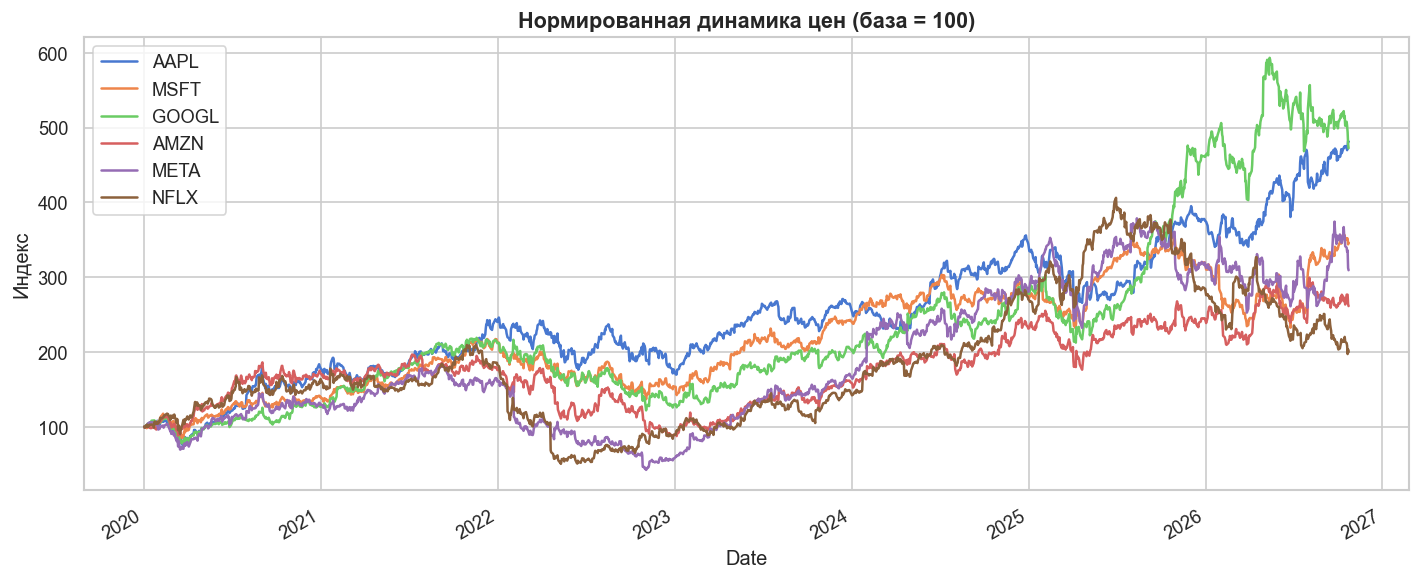

In [4]:
# Нормированная динамика цен (база = 100)
normalized = prices / prices.iloc[0] * 100

fig, ax = plt.subplots(figsize=(12, 5))
normalized.plot(ax=ax, linewidth=1.5)
ax.set_title("Нормированная динамика цен (база = 100)",
             fontsize=13,
             fontweight="bold")
ax.set_ylabel("Индекс")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

In [5]:
returns = compute_returns(prices, method="simple")
print("Дневные доходности — описательная статистика")
display(returns.describe().T.round(4))

Дневные доходности — описательная статистика


,count,mean,std,min,25%,50%,75%,max
Ticker,,,,,,,,
AAPL,1711.0,0.0011,0.0196,-0.1286,-0.0081,0.0012,0.0112,0.1533
MSFT,1711.0,0.0009,0.0191,-0.1474,-0.0085,0.0010,0.0105,0.1551
GOOGL,1711.0,0.0011,0.0204,-0.1163,-0.0096,0.0015,0.0116,0.1022
AMZN,1711.0,0.0008,0.0224,-0.1405,-0.0113,0.0006,0.0130,0.1532
META,1711.0,0.0010,0.0276,-0.2639,-0.0119,0.0010,0.0140,0.2328
NFLX,1711.0,0.0008,0.0271,-0.3512,-0.0116,0.0003,0.0134,0.1685


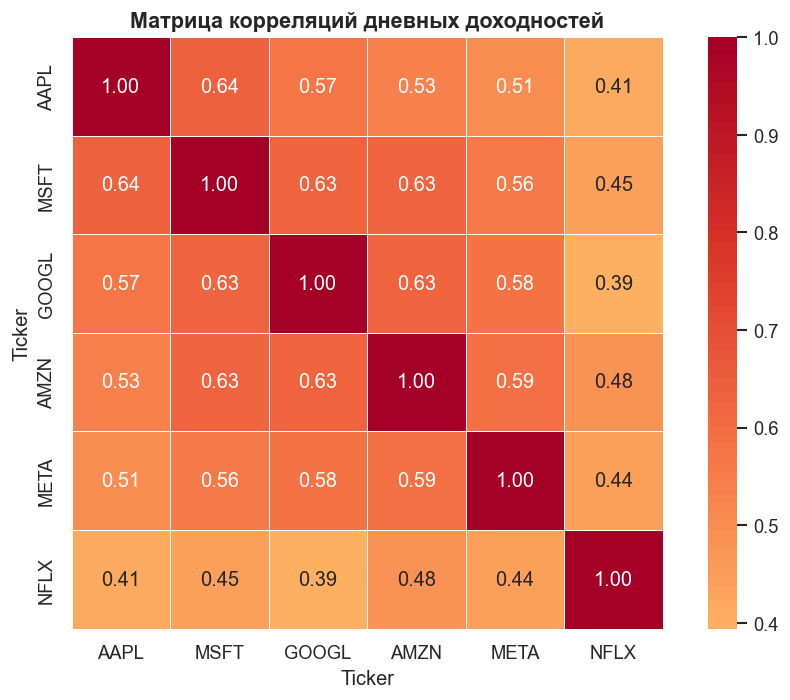

In [6]:
# Тепловая карта корреляций
corr = returns.corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr,
            annot=True,
            fmt=".2f",
            cmap="RdYlBu_r",
            center=0,
            square=True,
            linewidths=0.5,
            ax=ax)
ax.set_title("Матрица корреляций дневных доходностей",
             fontsize=13,
             fontweight="bold")
plt.tight_layout()
plt.show()

In [7]:
# Годовая волатильность
ann_vol = returns.std() * np.sqrt(252)
print("Годовая волатильность:")
print(ann_vol.round(3).sort_values(ascending=False))

Годовая волатильность:
Ticker
META     0.439
NFLX     0.431
AMZN     0.356
GOOGL    0.324
AAPL     0.312
MSFT     0.303
dtype: float64


## 4. Оценка параметров модели

Оцениваем вектор средних дневных доходностей и полную ковариационную матрицу.  
Именно эти параметры управляют движком Монте-Карло.


In [8]:
mean_returns, cov_matrix = get_portfolio_params(returns)

print("Средние дневные доходности:")
for t, m in zip(prices.columns, mean_returns):
    print(f"  {t:6s}: {m*100:6.3f}%  (год. ≈ {m*252*100:.1f}%)")

print("\nРазмер ковариационной матрицы:", cov_matrix.shape)

Средние дневные доходности:
  AAPL  :  0.111%  (год. ≈ 28.0%)
  MSFT  :  0.091%  (год. ≈ 22.9%)
  GOOGL :  0.112%  (год. ≈ 28.1%)
  AMZN  :  0.081%  (год. ≈ 20.5%)
  META  :  0.104%  (год. ≈ 26.3%)
  NFLX  :  0.078%  (год. ≈ 19.7%)

Размер ковариационной матрицы: (6, 6)


## 5. Симуляция Монте-Карло

Генерируем **10 000** коррелированных траекторий портфеля на следующие **252 торговых дня**, используя многомерное нормальное распределение, согласованное с историческими средними и ковариациями  
(дискретная аппроксимация многоактивного геометрического броуновского движения).


In [9]:
paths, final_values = run_monte_carlo_portfolio(
    mean_returns=mean_returns,
    cov_matrix=cov_matrix,
    weights=WEIGHTS,
    initial_value=INITIAL_CAPITAL,
    n_simulations=N_SIMULATIONS,
    n_days=HORIZON_DAYS,
    seed=42,
    show_progress=True,
)

print(f"\nСимуляция завершена. Форма конечных значений: {final_values.shape}")

Симуляции Монте-Карло: 100%|███████████| 10000/10000 [00:00<00:00, 33544.21it/s]


Симуляция завершена. Форма конечных значений: (10000,)


## 6. Метрики риска


In [10]:
metrics = calculate_risk_metrics(final_values, initial_value=INITIAL_CAPITAL)
print(summarize_simulations(final_values, INITIAL_CAPITAL))

=== Сводка результатов Монте-Карло анализа портфеля ===
Начальный капитал              : $100,000
Количество симуляций           : 10,000

Ожидаемая конечная стоимость   : $127,259
Медианная конечная стоимость   : $122,282
Стд. отклонение конечной ст-ти : $36,350

Средняя доходность             : 27.3%
Медианная доходность           : 22.3%

Вероятность убытка             : 23.6%
Вероятность роста +20% и более : 52.6%
Вероятность удвоения капитала  : 4.0%

VaR 95% (горизонт 1 год)       : $22,434  (22.4%)
CVaR 95% (Expected Shortfall)  : $30,490  (30.5%)
VaR 99%                        : $35,499  (35.5%)
CVaR 99%                       : $41,216  (41.2%)

5-й перцентиль                 : $77,566
95-й перцентиль                : $194,267


## 7. Визуализации


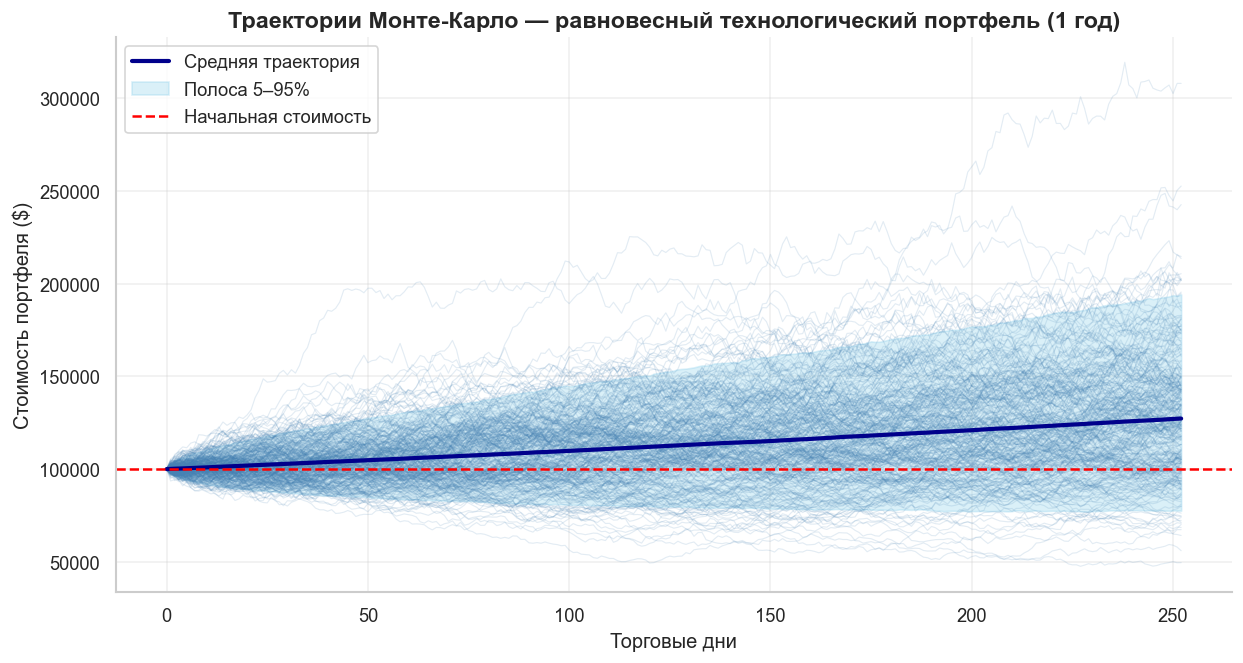

In [11]:
fig1 = plot_simulation_paths(
    paths,
    initial_value=INITIAL_CAPITAL,
    n_show=300,
    title=
    "Траектории Монте-Карло — равновесный технологический портфель (1 год)",
    save_path="../figures/simulation_paths.png",
)
plt.show()

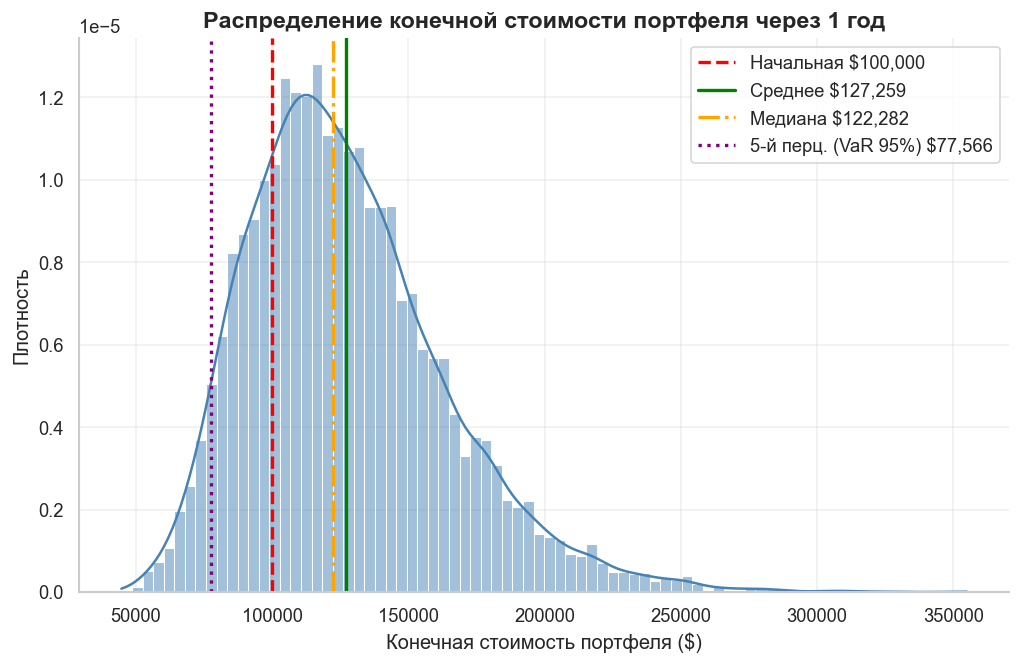

In [13]:
fig2 = plot_final_distribution(
    final_values,
    initial_value=INITIAL_CAPITAL,
    title="Распределение конечной стоимости портфеля через 1 год",
    save_path="../figures/final_distribution.png",
)
plt.show()

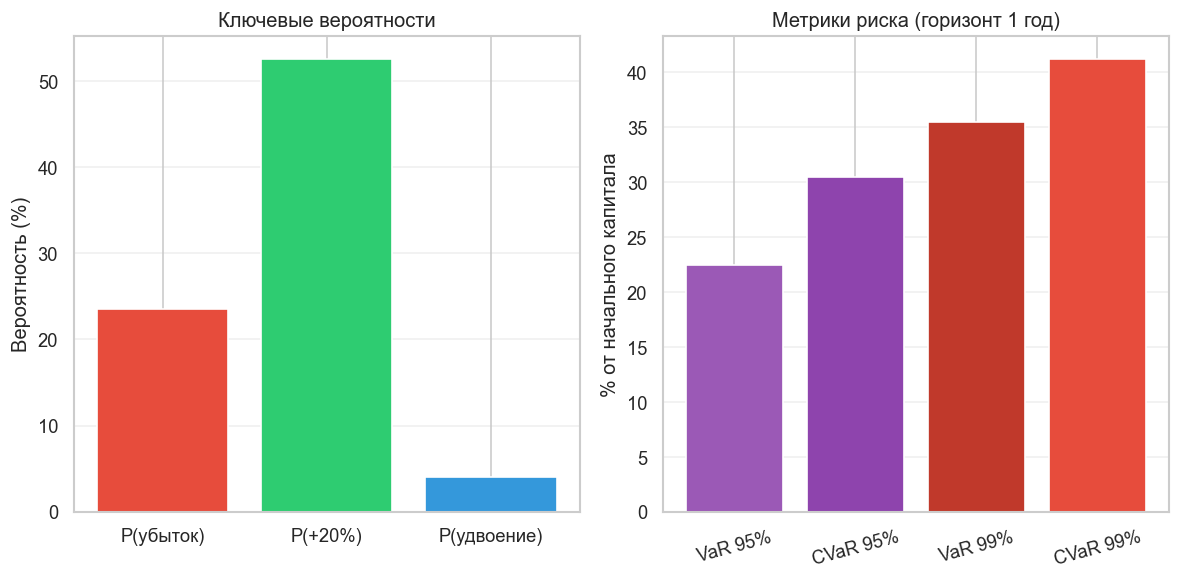

In [14]:
fig3 = plot_risk_metrics(metrics, save_path="../figures/risk_metrics.png")
plt.show()

## 8. Ключевые выводы и интерпретация

- **Ожидаемый результат**: среднее и медиана конечной стоимости показывают центральную тенденцию портфеля при историческом режиме доходностей.
- **Риск снижения**: VaR 95% отвечает на вопрос «Какой максимальный убыток я могу ожидать с уверенностью 95% в течение следующего года?». CVaR идёт дальше и показывает **средний убыток в худших 5% сценариев**.
- **Вероятность убытка**: даже исторически сильный технологический портфель имеет ненулевую вероятность закончить год в минусе — Монте-Карло делает эту вероятность явной.
- **Тяжёлые хвосты и корреляции**: благодаря использованию полной ковариационной матрицы периоды высокой корреляции (кризисные режимы) частично отражаются в совместных движениях активов.
- **Практическое применение**: эти цифры можно использовать для определения размера позиций, распределения капитала, стресс-тестирования или общения со стейкхолдерами о риск-аппетите.

### Возможные расширения
- Оптимизировать веса (mean-variance / risk-parity) перед симуляцией  
- Regime-switching или модели волатильности GARCH  
- Учесть транзакционные издержки и ребалансировку  
- Бутстрап исторических доходностей вместо параметрического нормального предположения  
- Анализ на нескольких горизонтах (3 месяца / 3 года)

## 9. Как воспроизвести

```bash
git clone <этот-репозиторий>
cd monte-carlo-portfolio-risk
python -m venv venv
source venv/bin/activate   # или аналог для Windows
pip install -r requirements.txt
jupyter notebook notebooks/01_monte_carlo_portfolio_analysis.ipynb
```

Ноутбук при каждом запуске скачивает свежие данные (требуется интернет).


---
*Проект создан для портфолио Data Scientist. Только в образовательных целях.*
